<a href="https://colab.research.google.com/github/tanu100/DeepLearning/blob/main/GradientDescent/Mini_BatchGradientDescent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns

In [13]:
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

In [14]:
x,y=make_regression(n_features=3,n_samples=10000,random_state=42,noise=0.2)

In [15]:
X_train,x_test,Y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.3)

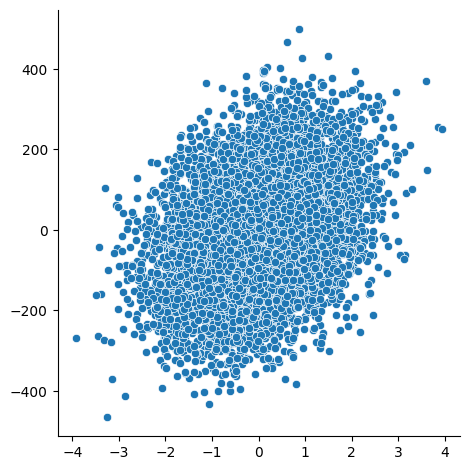

In [52]:
sns.relplot(x=x[:, 0], y=y, kind="scatter")

In [17]:
print(len(X_train))
print(len(Y_train))
print(len(x_test))
print(len(y_test))



7000
7000
3000
3000


In [47]:
class MiniBGD:
  def __init__(self,c=0,m=0,epoch=10,lr=0.01,batch=100):
    self.c=c
    self.m=m

    self.lr=lr
    self.epoch=epoch
    self.batch=batch

  def fit(self,X_train,Y_train):
    self.m=np.zeros(X_train.shape[1])


    for _ in range(self.epoch):

      for start in range(0,X_train.shape[0],self.batch):

        X_batch=X_train[start : start+self.batch]
        Y_batch=Y_train[start : start+self.batch]


        # Calculate predicted values using y = mx + c
        y_hat = self.c + (X_batch @ self.m)

        # Calculate gradient of the loss with respect to intercept (c)
        dc = -2 * np.mean(Y_batch - y_hat)

        # Calculate gradient of the loss with respect to coefficients (m)
        dm = -2 * ((Y_batch - y_hat) @ X_batch) / X_batch.shape[0]

        # Update intercept using the learning rate
        self.c = self.c - (self.lr * dc)

        # Update coefficients using the learning rate
        self.m = self.m - (self.lr * dm)


  def predict(self,x_test):
     return self.c + x_test@self.m


In [44]:
lr=LinearRegression()
lr.fit(X_train,Y_train)
print("intercept of equation",lr.intercept_)
print("cofficents of equations ",lr.coef_)
arr1=lr.predict(x_test)
print(arr1)

intercept of equation 0.0013884060104775164
cofficents of equations  [43.32492571 88.16711621 83.18805164]
[ 134.97312025  108.7314771    27.35777585 ...  -76.25808954 -125.94594594
   94.19709132]


In [48]:
testobj=MiniBGD()
print(testobj.fit(X_train,Y_train))
print("cofficents of equations " , testobj.m)
print("intercept of equation",testobj.c)
print(testobj.predict(x_test))

None
cofficents of equations  [43.32436919 88.16721441 83.1883075 ]
intercept of equation -0.0005573137930924713
[ 134.9712054   108.72983912   27.35485216 ...  -76.25993295 -125.94745343
   94.19523694]
